In [90]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import math
import plotly.io as pio
pio.renderers.default = "png"

# Example 10.1 : Mountain Car Task

For this task, 8 tilings are used, where each tile covers 1/8th of the bounded distance in each dimension.  

Let $[a, b] \times [c, d]$ be the domain of each dimension, and let $n$ be the number of tilings in a general framework. We denote by $\omega_x, \omega_y$ the elementary distance covered by one tile in each dimension, i.e, $\omega_x = (b - a) / n$ and $\omega_y = (d - c) / n$, and we consider offset tilings with vector $(o_x, o_y)$ (In the example, $(o_x, o_y) = (3, 1)$).  
Except the first tiling (that starts exactly at $(a, c)$), each tiling has $(n + 1) \times (n + 1)$ number of tiles in total. For generalisation sake, we consider that it is the case for all tilings (by allowing empty tiles for the $(a, c)$ tiling).  

For each tiling $T_i, \ i \in \{0, 1, \dots, n-1 \}$, we consider the "origin" point of the tiling within the first (unempty) tile of Tiling 0 : $[a, a + \omega_x] \times [c, c + \omega_y]$. To Tiling 0, we associate the lower left point of the tile $(a, c)$. To the rest of the tilings, the general expression for the origin point is : $$(a + \frac{io_x \mod n}{n}\omega_x, \ c + \frac{io_y \mod n}{n}\omega_y)$$

This allows us to derive the domains of the tiles of each tiling. Let $(k, l) \in \llbracket 0, n \rrbracket^2$ be the "coordinates" of a tile in Tiling $i$. The domain covered by the corresponding tile is such as :
\begin{align*}
  T_i^{(k, l)} &= \left[ \max \left(a, \ a + \frac{io_x \mod n}{n}\omega_x + (k-1)\omega_x \right), \ \min \left (a + \frac{io_x \mod n}{n}\omega_x + k\omega_x, \ b \right ) \right] \\
               & \times \left [\max \left (c, \ c + \frac{io_y \mod n}{n}\omega_y + (l-1)\omega_y \right ), \ \min \left (c + \frac{io_y \mod n}{n}\omega_y + l\omega_y, \ d \right) \right]
\end{align*}

Finally, for every $(x, y) \in [a, b] \times [c, d]$, we derive the corresponding tile in every tiling $i$ by looking for the smallest $k$ and $l$ such that :
\begin{cases}
x < a + \frac{io_x \mod n}{n}\omega_x + k\omega_x & \\
y < c + \frac{io_y \mod n}{n}\omega_y + l\omega_y &
\end{cases}

so that :
$$ k = \left \lceil \frac{x-a}{\omega_x} - \frac{io_x \mod n}{n} \right \rceil, \quad l = \left \lceil \frac{y-b}{\omega_y} - \frac{io_y \mod n}{n} \right \rceil$$

In [91]:
def identifyTile(x, y, nTiles, i, a, b, c, d, ox=3, oy=1):
    omegaX = (b - a) / nTiles
    omegaY = (d - c) / nTiles
    k = math.ceil((x - a) / omegaX - ((i * ox) % nTiles) / nTiles)
    l = math.ceil((y - c) / omegaY - ((i * oy) % nTiles) / nTiles)

    if i == 0:
        k = max(k, 1)
        l = max(l, 1)
    return k, l

In [92]:
def computeQ(position, velocity, Wr, Wz, Wf, nTilings, a, b, c, d):
    tiles = tuple(np.array([(i, *identifyTile(position, velocity, nTilings, i, a, b, c, d)) for i in range(nTilings)]).T)
    return Wr[tiles].sum(), Wz[tiles].sum(), Wf[tiles].sum()

In [93]:
def episodicSGSarsaMC(nEpisodes, alpha, epsilon, nTilings=8, a=-1.2, b=0.5, c=-0.07, d=0.07, ls=-0.6, us=-0.4):
    Wreverse = np.zeros((nTilings, nTilings + 1, nTilings + 1))
    Wforward = np.zeros((nTilings, nTilings + 1, nTilings + 1))
    Wzero = np.zeros((nTilings, nTilings + 1, nTilings + 1))

    nSteps = np.empty(nEpisodes, dtype=int)

    for episode in range(nEpisodes):
        stepCount = 0
        currentPosition = ls + (us - ls) * np.random.rand()
        currentVelocity = 0
        qCurrentState = computeQ(currentPosition, currentVelocity, Wreverse, Wzero, Wforward, nTilings, a, b, c, d)
        if np.random.rand() < epsilon:
            currentAction = np.random.choice([-1, 0, 1])
        else:
            qMax = np.max(qCurrentState)
            currentAction = np.random.choice([action for action in [-1, 0, 1] if qCurrentState[action + 1] == qMax])
        
        terminal = False
        while not terminal:
            nextVelocity = min(max(c, currentVelocity + 0.001 * currentAction - 0.0025 * np.cos(3 * currentPosition)), d)
            nextPosition = min(max(a, currentPosition + nextVelocity), b)
            stepCount += 1

            if nextPosition == a:
                nextVelocity = 0
            elif nextPosition == b:
                terminal = True
                update = alpha * (0 - qCurrentState[currentAction + 1])
            
            if not terminal:
                qNextState = computeQ(nextPosition, nextVelocity, Wreverse, Wzero, Wforward, nTilings, a, b, c, d)
                if np.random.rand() < epsilon:
                    nextAction = np.random.choice([-1, 0, 1])
                else:
                    qMax = np.max(qNextState)
                    nextAction = np.random.choice([action for action in [-1, 0, 1] if qNextState[action + 1] == qMax])
                
                update = alpha * (-1 + qNextState[nextAction + 1] - qCurrentState[currentAction + 1])

            for tiling in range(nTilings):
                currentTile = identifyTile(currentPosition, currentVelocity, nTilings, tiling, a, b, c, d)
                if currentAction == -1:
                    Wreverse[tiling][currentTile] += update
                elif currentAction == 0:
                    Wzero[tiling][currentTile] += update
                else:
                    Wforward[tiling][currentTile] += update
            
            if terminal:
                break
            
            currentPosition = nextPosition
            currentVelocity = nextVelocity
            currentAction = nextAction
            qCurrentState = computeQ(currentPosition, currentVelocity, Wreverse, Wzero, Wforward, nTilings, a, b, c, d)
        
        nSteps[episode] = stepCount

    return nSteps
    

In [94]:
alphasMC = [0.1, 0.2, 0.5]
nRepsMC = 100
epsilonMC = 0.001
nEpisodesMC = 500
nTilingsMC = 8

nStepsAvgMC = []
for alpha in alphasMC:
    print(alpha)
    nStepsAlpha = []
    for rep in range(nRepsMC):
        nStepsAlpha.append(episodicSGSarsaMC(nEpisodesMC, alpha / nTilingsMC, epsilonMC))

    nStepsAvgMC.append(np.mean(nStepsAlpha, axis=0))

0.1
0.2
0.5


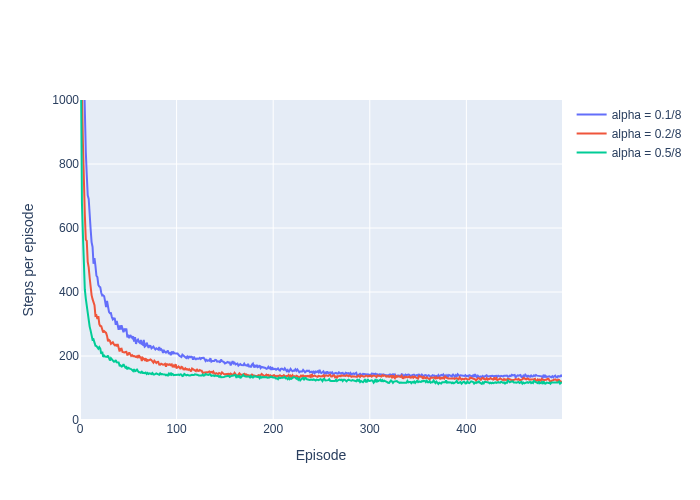

In [95]:
fig = go.Figure()
fig.add_trace(go.Scatter(y=nStepsAvgMC[0], name="alpha = 0.1/8"))
fig.add_trace(go.Scatter(y=nStepsAvgMC[1], name="alpha = 0.2/8"))
fig.add_trace(go.Scatter(y=nStepsAvgMC[2], name="alpha = 0.5/8"))
fig.update_yaxes(range=[0, 1000])
fig.update_layout(xaxis_title="Episode", yaxis_title="Steps per episode")

# Semi-gradient $n$-step Sarsa

In [96]:
def episodicSGnStepSarsaMC(nEpisodes, alpha, epsilon, n, nTilings=8, a=-1.2, b=0.5, c=-0.07, d=0.07, ls=-0.6, us=-0.4):
    Wreverse = np.zeros((nTilings, nTilings + 1, nTilings + 1))
    Wforward = np.zeros((nTilings, nTilings + 1, nTilings + 1))
    Wzero = np.zeros((nTilings, nTilings + 1, nTilings + 1))

    nSteps = np.empty(nEpisodes, dtype=int)

    for episode in range(nEpisodes):
        currentPosition = ls + (us - ls) * np.random.rand()
        currentVelocity = 0
        positionTrajectory = []
        velocityTrajectory = []
        actionTrajectory = []

        qCurrentState = computeQ(currentPosition, currentVelocity, Wreverse, Wzero, Wforward, nTilings, a, b, c, d)
        positionTrajectory.append(currentPosition)
        velocityTrajectory.append(currentVelocity)
        if np.random.rand() < epsilon:
            currentAction = np.random.choice([-1, 0, 1])
        else:
            qMax = np.max(qCurrentState)
            currentAction = np.random.choice([action for action in [-1, 0, 1] if qCurrentState[action + 1] == qMax])

        actionTrajectory.append(currentAction)

        T = np.inf
        t = 0
        tau = t - n + 1
        terminal = False
        while tau < T - 1:
            if t < T:
                nextVelocity = min(max(c, currentVelocity + 0.001 * currentAction - 0.0025 * np.cos(3 * currentPosition)), d)
                nextPosition = min(max(a, currentPosition + nextVelocity), b)

                if nextPosition == a:
                    nextVelocity = 0
                elif nextPosition == b:
                    T = t + 1
                    terminal = True

                if not terminal:
                    positionTrajectory.append(nextPosition)
                    velocityTrajectory.append(nextVelocity)
                    
                    qNextState = computeQ(nextPosition, nextVelocity, Wreverse, Wzero, Wforward, nTilings, a, b, c, d)
                    if np.random.rand() < epsilon:
                        nextAction = np.random.choice([-1, 0, 1])
                    else:
                        qMax = np.max(qNextState)
                        nextAction = np.random.choice([action for action in [-1, 0, 1] if qNextState[action + 1] == qMax])

                    actionTrajectory.append(nextAction)

                    currentPosition = nextPosition
                    currentVelocity = nextVelocity
                    currentAction = nextAction

            tau = t - n + 1
            if tau >= 0:
                update = -(min(tau + n, T) - tau)
                if tau + n < T:
                    update += qNextState[nextAction + 1]

                qTau = computeQ(positionTrajectory[tau], velocityTrajectory[tau], Wreverse, Wzero, Wforward, nTilings, a, b, c, d)
                update -= qTau[actionTrajectory[tau] + 1]
                update *= alpha

                for tiling in range(nTilings):
                    currentTile = identifyTile(positionTrajectory[tau], velocityTrajectory[tau], nTilings, tiling, a, b, c, d)
                    if actionTrajectory[tau] == -1:
                        Wreverse[tiling][currentTile] += update
                    elif actionTrajectory[tau] == 0:
                        Wzero[tiling][currentTile] += update
                    else:
                        Wforward[tiling][currentTile] += update

            t += 1

        nSteps[episode] = T


    return nSteps

In [97]:
nRepsBootstrapMC = 100
epsilonBootstrapMC = 0.001
nEpisodesBootstrapMC = 500
nTilingsBootstrapMC = 8

nStepsBootstrapMC1 = []
nStepsBootstrapMC8 = []

for rep in range(nRepsBootstrapMC):
    nStepsBootstrapMC1.append(episodicSGnStepSarsaMC(nEpisodesBootstrapMC, 0.5 / nTilingsBootstrapMC, epsilonBootstrapMC, 1))
    nStepsBootstrapMC8.append(episodicSGnStepSarsaMC(nEpisodesBootstrapMC, 0.3 / nTilingsBootstrapMC, epsilonBootstrapMC, 8))

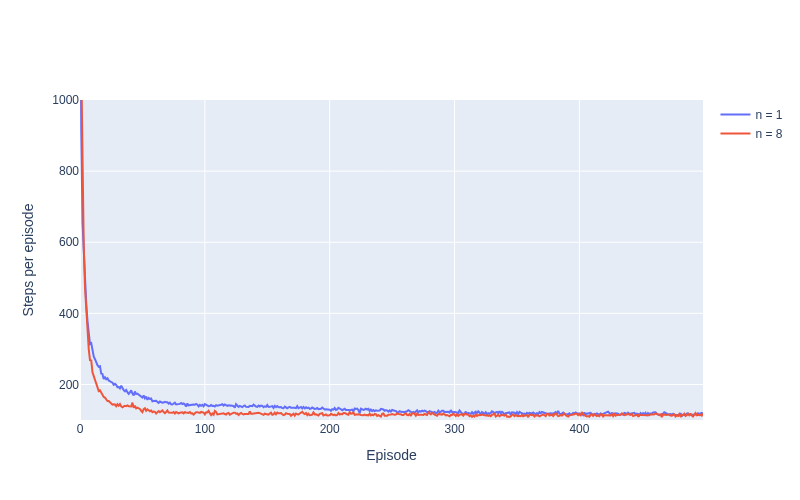

In [98]:
fig = go.Figure()
fig.add_trace(go.Scatter(y=np.mean(nStepsBootstrapMC1, axis=0), name="n = 1"))
fig.add_trace(go.Scatter(y=np.mean(nStepsBootstrapMC8, axis=0), name="n = 8"))
fig.update_layout(xaxis_title="Episode", yaxis_title="Steps per episode", width=800)
fig.update_yaxes(range=[100, 1000])

In [99]:
nEpisodes = 50
nReps = 100
nList = 2 ** np.arange(5)
alphas = {1: np.linspace(0.1, 1.7, 50), 2: np.linspace(0.1, 1.7, 50), 4: np.linspace(0.1, 1.5, 50), 8: np.linspace(0.1, 1, 50), 16: np.linspace(0.1, 0.7, 50)}

avgs = {}
for n in nList:
    avgs[n] = []
    for alpha in alphas[n]:
        nAlphaSteps = []
        for rep in range(nReps):
            nAlphaSteps.append(np.mean(episodicSGnStepSarsaMC(nEpisodes, alpha / 8, 0, n)))
        avgs[n].append(np.mean(nAlphaSteps))

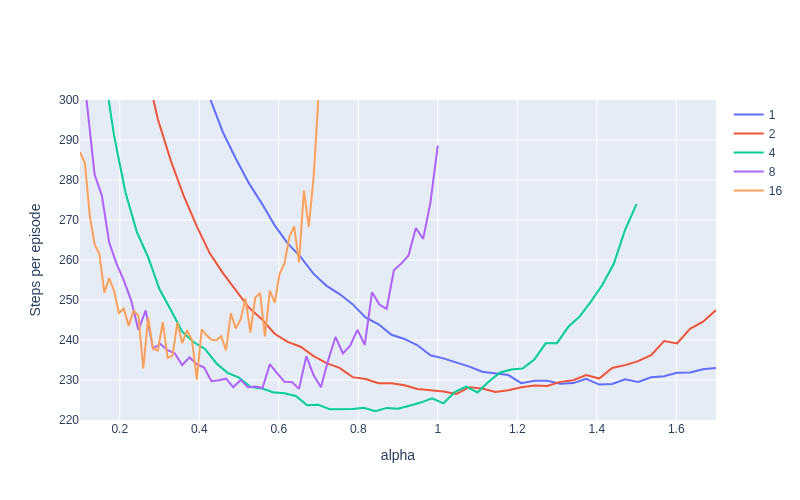

In [107]:
fig = go.Figure()
for n in nList:
    fig.add_trace(go.Scatter(x=alphas[n], y=avgs[n], name=str(n)))
fig.update_layout(width=800, xaxis_title="alpha", yaxis_title="Steps per episode")
fig.update_yaxes(range=[220, 300])
fig.show()

# Access-Control Queuing Task

In [101]:
def differentialSGSarsa(maxIter, qInit, alpha, beta, epsilon):
    Q = qInit.copy()
    R = 0

    iter = 0
    currentFreeServers = 10
    currentPriority = np.random.choice([0, 1, 2, 3])
    if np.random.rand() < epsilon:
        currentAction = np.random.choice([0, 1])
    else:
        qMax = np.max(Q[currentFreeServers, currentPriority])
        currentAction = np.random.choice([action for action in [0, 1] if Q[currentFreeServers, currentPriority, action] == qMax])
        
    while iter < maxIter:
        currentReward = currentAction * (2 ** currentPriority)
        nextFreeServers = currentFreeServers - currentAction + np.random.binomial(10 - currentFreeServers, 0.06)

        nextPriority = np.random.choice([0, 1, 2, 3])
        nextAction = 0
        if nextFreeServers:
            if np.random.rand() < epsilon:
                nextAction = np.random.choice([0, 1])
            else:
                qMax = np.max(Q[nextFreeServers, nextPriority])
                nextAction = np.random.choice([action for action in [0, 1] if Q[nextFreeServers, nextPriority, action] == qMax])

        delta = currentReward - R + Q[nextFreeServers, nextPriority, nextAction] - Q[currentFreeServers, currentPriority, currentAction]
        R += beta * delta
        Q[currentFreeServers, currentPriority, currentAction] += alpha * delta
        
        currentFreeServers = nextFreeServers
        currentPriority = nextPriority
        currentAction = nextAction
        iter += 1

    return Q, R

In [102]:
qInit = np.zeros((11, 4, 2))
qInit[0, :, 1] = -np.inf ## Can't accept when there are no free servers !
qStarACQT, RStarACQT = differentialSGSarsa(5000000, qInit, 0.01, 0.01, 0.1)

In [103]:
RStarACQT

np.float64(2.5724536193120526)

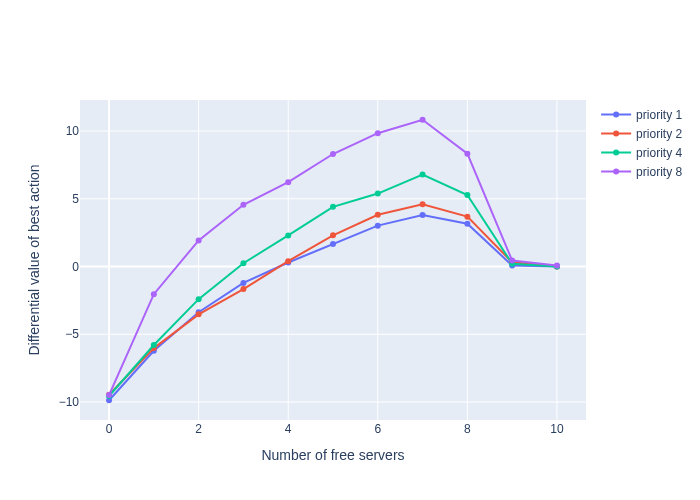

In [104]:
vStarACQT = np.max(qStarACQT, axis=2)
fig = go.Figure()
fig.add_trace(go.Scatter(y=vStarACQT[:, 0], name="priority 1"))
fig.add_trace(go.Scatter(y=vStarACQT[:, 1], name="priority 2"))
fig.add_trace(go.Scatter(y=vStarACQT[:, 2], name="priority 4"))
fig.add_trace(go.Scatter(y=vStarACQT[:, 3], name="priority 8"))
fig.update_layout(width=700, xaxis_title="Number of free servers", yaxis_title="Differential value of best action")

In [105]:
def plotPolicyACQT(policy):
    x = np.arange(11)
    y = np.arange(4)
 
    fig = go.Figure()
 
    Xy1, Yy1 = np.meshgrid(x, y[1:])
    Xy_1, Yy_1 = np.meshgrid(x, y[:-1])
    Xx1, Yx1 = np.meshgrid(x[1:], y)
    Xx_1, Yx_1 = np.meshgrid(x[:-1], y)
 
    diff_x = policy[:, ::-1][Xx1, Yx1] != policy[:, ::-1][Xx_1, Yx_1]
    diff_y = policy[:, ::-1][Xy1, Yy1] != policy[:, ::-1][Xy_1, Yy_1]

    iy, ix = np.where(diff_x)
    for i, j in zip(ix, iy):
        fig.add_trace(
            go.Scatter(
                x=[i, i],
                y=[j, j+1],
                mode="lines",
                line=dict(color="black"),
                showlegend=False,
                hoverinfo="none"
            )
        )

    iy, ix = np.where(diff_y)
    for i, j in zip(ix, iy):
        fig.add_trace(
            go.Scatter(
                x=[i-1, i],
                y=[j+1, j+1],
                mode="lines",
                line=dict(color="black"),
                showlegend=False,
                hoverinfo="none"
            )
        )

    fig.update_xaxes(range=[0, 10], tickmode="array", tickvals=np.arange(11), ticks="inside", dtick=1, showticklabels=False)

    for i in range(11):
        fig.add_annotation(
            x=i + 0.5,
            y=0,
            xref=f"x",
            yref=f"y domain",
            text=str(i + 1),
            showarrow=False,
            yshift=-25,
        )

    fig.update_yaxes(range=[0, 4], tickvals=np.arange(4), ticktext=2**np.arange(0, 4, -1), ticks="inside", dtick=1, showticklabels=False)
        
    for i in range(4):
        fig.add_annotation(
            y=i + 0.5,
            x=0,
            xref=f"x",
            yref=f"y",
            text=str(2 ** (3 - i)),
            showarrow=False,
            xshift=-25,
        )
               
    fig.update_layout(showlegend=False, width=700, height=400,
                      xaxis_title="Number of free servers", yaxis_title="Priority")
    fig.update_xaxes(title_standoff=30)
    fig.update_yaxes(title_standoff=40)

    fig.show()

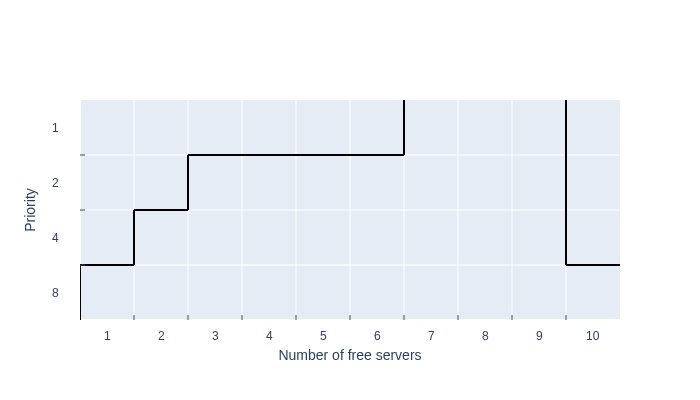

In [106]:
policyStarACQT = np.argmax(qStarACQT, axis=2)
plotPolicyACQT(policyStarACQT)